## Chi-Square Tests

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Build contingency table and goodness-of-fit data
# Independence example: gender vs voting (counts, not percentages)
observed = np.array([
    [30, 50],  # Male: 30 voted, 50 not
    [50, 30]   # Female: 50 voted, 30 not
])

# Goodness-of-fit example: 120 dice rolls, is the die fair?
dice_obs = np.array([15, 25, 10, 20, 30, 20])
dice_exp = np.array([20, 20, 20, 20, 20, 20])  # Fair die expects 20 each

print("Contingency table (Gender x Vote):")
print(pd.DataFrame(observed, index=["Male", "Female"], columns=["Voted", "Not"]))
print(f"\nDice observed: {dice_obs}")
print(f"Dice expected: {dice_exp}")

Contingency table (Gender x Vote):
        Voted  Not
Male       30   50
Female     50   30

Dice observed: [15 25 10 20 30 20]
Dice expected: [20 20 20 20 20 20]


In [3]:
# Test independence and goodness-of-fit
alpha = 0.05

# 1. Test of Independence: H0 = gender and vote are independent
chi2, p, dof, expected = stats.chi2_contingency(observed)
print(f"Independence: chi2={chi2:.3f}, df={dof}, p={p:.4f}")
print("Expected under H0:")
print(np.round(expected, 1))
print(f"-> {'significant relation' if p < alpha else 'no evidence of relation'}")

# Cramer's V for effect size
n = observed.sum()
v = np.sqrt(chi2 / (n * (min(observed.shape) - 1)))
print(f"Cramer's V={v:.3f} (0.1 weak, 0.3 medium, 0.5 strong)")

# 2. Goodness-of-Fit: H0 = die is fair
chi2_g, p_g = stats.chisquare(f_obs=dice_obs, f_exp=dice_exp)
print(f"\nGoodness-of-Fit: chi2={chi2_g:.3f}, p={p_g:.4f}")
print(f"-> {'die is NOT fair' if p_g < alpha else 'fits fair die'}")

Independence: chi2=9.025, df=1, p=0.0027
Expected under H0:
[[40. 40.]
 [40. 40.]]
-> significant relation
Cramer's V=0.238 (0.1 weak, 0.3 medium, 0.5 strong)

Goodness-of-Fit: chi2=12.500, p=0.0285
-> die is NOT fair


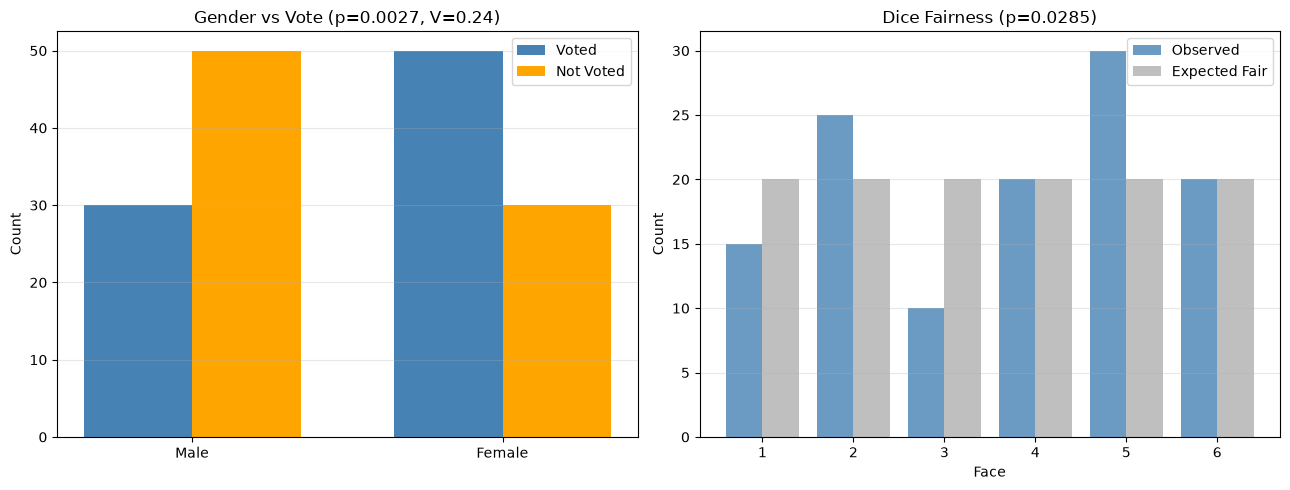

In [4]:
# Visualize observed vs expected gaps
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left plot: grouped bars show the gender-vote pattern clearly
x = np.arange(2)
width = 0.35
axes[0].bar(x - width/2, observed[:, 0], width, color="steelblue", label="Voted")
axes[0].bar(x + width/2, observed[:, 1], width, color="orange", label="Not Voted")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Male", "Female"])
axes[0].set_title(f"Gender vs Vote (p={p:.4f}, V={v:.2f})")
axes[0].set_ylabel("Count")
axes[0].legend()
axes[0].grid(alpha=0.3, axis="y")

# Right plot: dice observed vs fair expectation
faces = np.arange(1, 7)
axes[1].bar(faces - 0.2, dice_obs, width=0.4, color="steelblue", alpha=0.8, label="Observed")
axes[1].bar(faces + 0.2, dice_exp, width=0.4, color="gray", alpha=0.5, label="Expected Fair")
axes[1].set_xticks(faces)
axes[1].set_title(f"Dice Fairness (p={p_g:.4f})")
axes[1].set_xlabel("Face")
axes[1].set_ylabel("Count")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

In [5]:
# Experiment - bigger n and tiny expected counts
# Same percentages but 10x sample: tiny gap becomes significant
big_table = observed * 10
chi2_big, p_big, _, _ = stats.chi2_contingency(big_table)
print(f"Original n={observed.sum()}: p={p:.4f} | 10x n={big_table.sum()}: p={p_big:.5f}")

# Warning case: one cell with expected < 5 breaks the assumption
small_table = np.array([[8, 2], [3, 2]])
chi2_s, p_s, _, exp_s = stats.chi2_contingency(small_table)
print(f"Small table expected:\n{np.round(exp_s, 2)}")
print(f"Small table: p={p_s:.4f} (unreliable, expected < 5)")

# Question: Why did the same pattern give a much smaller p with 10x data?
# Question: What should you do when an expected count is below 5?

Original n=160: p=0.0027 | 10x n=1600: p=0.00000
Small table expected:
[[7.33 2.67]
 [3.67 1.33]]
Small table: p=0.8365 (unreliable, expected < 5)
